# Predicción de Popularidad Musical en Spotify
## Notebook 2: Modelamiento, Evaluación y Análisis Ético

### Resumen
Este notebook implementa el ciclo completo de ciencia de datos sobre el
dataset `spotify_tracks_clean.csv` generado en el notebook ev1. Se cubren
las siguientes etapas:

1. Comprensión del problema de negocio y definición de KPIs.
2. Verificación de calidad del dataset procesado y síntesis del EDA de ev1.
3. Preparación y transformación de datos (ingeniería de características,
   codificación de alta cardinalidad, escalamiento, balanceo).
4. Implementación y comparación de tres modelos supervisados de clasificación
   (Random Forest, XGBoost, Regresión Logística).
5. Implementación de un modelo no supervisado (PCA + K-Means) orientado al
   descubrimiento de segmentos sonoros.
6. Evaluación de desempeño con métricas apropiadas al desbalance de clases,
   incluyendo análisis desagregado por género y por segmento.
7. Análisis de sesgos y consideraciones éticas heredadas del EDA.

### Decisiones metodológicas clave
- Se reemplaza el uso de SMOTE por `class_weight` como estrategia de balanceo.
  Justificación en Sección 3.
- Se incorpora codificación de objetivo (Target Encoding) con validación
  cruzada para las variables `artists` y `album_name`. Justificación en
  Sección 3.
- El umbral de decisión se optimiza en un conjunto de validación y se evalúa
  con F2, métrica alineada con el KPI de negocio. Justificación en Sección 4.
- El desempeño por género se reporta con conteo de positivos por clase para
  distinguir entre limitación del modelo y ausencia de señal en el dato.
  Justificación en Sección 6.

## 0. Comprensión del problema de negocio y definición de KPIs

### Contexto
La industria musical opera bajo alta incertidumbre respecto al éxito
comercial de una canción. Plataformas como Spotify reciben miles de
lanzamientos diarios y los sellos deben decidir en qué pistas invertir
presupuesto promocional antes de conocer su desempeño real.

El dataset contiene características acústicas objetivas (energía,
bailabilidad, valence, tempo, entre otras), metadatos del artista y del
álbum, y la variable `popularity` en escala 0-100. La pregunta de negocio
es: ¿es posible anticipar, solo con información disponible al momento del
lanzamiento, si una canción alcanzará un umbral de popularidad relevante?

### Objetivo general
Construir y comparar modelos de aprendizaje automático que estimen la
probabilidad de que una canción se convierta en un éxito comercial,
entendiendo como éxito una popularidad mayor o igual a 50 en la escala de
Spotify. Este umbral corresponde aproximadamente al percentil 75 de la
distribución global y define la clase positiva en el problema de
clasificación.

### Objetivos específicos
- Comparar el desempeño de tres modelos supervisados de clasificación
  (Random Forest, XGBoost y Regresión Logística) en la predicción de hits.
- Identificar segmentos sonoros latentes mediante técnicas no supervisadas
  (PCA y K-Means) y analizar su relación con la probabilidad de hit.
- Evaluar el desempeño del modelo con métricas apropiadas para clases
  desbalanceadas y reportar el comportamiento por género musical.
- Analizar sesgos y consideraciones éticas derivados del problema y del
  conjunto de datos, incorporando los hallazgos del EDA de ev1.

### KPIs del proyecto

| KPI | Definición | Meta |
|---|---|---|
| Recall@Hit | Proporción de hits reales identificados por el modelo | >= 0.70 |
| F1-Score | Media armónica entre precision y recall | Maximizar, referencia >= 0.60 |
| PR-AUC | Área bajo la curva precision-recall | Mayor que prevalencia base (0.237) |
| ROC-AUC | Capacidad de discriminación global | >= 0.80 |
| MAE de popularidad | Error absoluto medio en escala 0-100 | <= 15 puntos |
| Diversidad | Cobertura de géneros entre los hits predichos | >= 15 géneros |

### Métricas éticas complementarias
- F1 por género con conteo de positivos.
- Distribución de hits predichos entre segmentos sonoros.
- Comparación entre el desempeño en géneros mainstream y de nicho.

## 1. Configuración e importación de librerías

Se silencian advertencias de convergencia y de versiones futuras que no
afectan el resultado. Requisitos mínimos:
- scikit-learn >= 1.3 (por TargetEncoder estable)
- xgboost >= 1.7
- imbalanced-learn no es requerido en esta versión

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    f1_score, recall_score, precision_score, accuracy_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_recall_curve, confusion_matrix, classification_report,
    silhouette_score
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 200)
sns.set_style('whitegrid')
print("Entorno configurado")

Entorno configurado


## 2. Carga del dataset y verificación de calidad

El dataset `spotify_tracks_clean.csv` proviene del notebook ev1, que aplicó
limpieza de nulos, depuración de registros inválidos (compases fuera del
rango 3-7, tempo nulo) y consolidación de duplicados por `track_id` con
codificación multi-etiqueta de géneros.

La verificación en esta sección es defensiva: se valida que las columnas
críticas no contengan valores nulos, que la variable objetivo esté bien
formada y que no existan filas con todas las características acústicas en
nulo (registros truncados). Si cualquiera de estas condiciones falla, el
pipeline detiene su ejecución antes de entrenar, evitando reproducir
resultados sobre datos corruptos.

In [ ]:
df = pd.read_csv("spotify_tracks_clean.csv")

core_audio = [
    'explicit', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
    'time_signature'
]

n_antes = len(df)
df = df.dropna(subset=core_audio).reset_index(drop=True)
df['explicit'] = df['explicit'].astype(int)
df['is_hit']   = (df['popularity'] >= 50).astype(int)

genre_cols = [c for c in df.columns if c.startswith('genre_')]
active = df[genre_cols].sum(axis=1)
df['genre'] = df[genre_cols].idxmax(axis=1).str.replace('genre_', '')
df.loc[active == 0, 'genre'] = 'unknown'

print(f"Filas iniciales:  {n_antes:,}")
print(f"Filas utilizables: {len(df):,}")
print(f"Eliminadas:       {n_antes - len(df)}")
print(f"Prevalencia hit global: {df['is_hit'].mean():.4f}")
print(f"Valores nulos totales:  {df.isnull().sum().sum()}")

Filas iniciales:  88,732
Filas utilizables: 88,732
Eliminadas:       0
Prevalencia hit global: 0.2372
Valores nulos totales:  0


## 3. Síntesis del análisis exploratorio y de sesgos (ev1)

Los hallazgos del notebook ev1 que condicionan las decisiones de modelado
son los siguientes.

### Hallazgos sobre la calidad y estructura del dato
- El dataset original contenía 114,000 filas y se redujo a 88,732 canciones
  únicas (22.16%), principalmente por consolidación de duplicados
  entre géneros. Sin esta consolidación, la misma canción aparecía varias
  veces con distintos géneros, generando fuga de datos entre train y test.
- La variable `popularity` presenta una concentración alta en valores bajos
  (cerca del 30% de las canciones tiene popularidad menor a 20).
  El umbral de 50 corresponde aproximadamente al percentil 75.
- Las variables `duration_ms`, `speechiness` e `instrumentalness` presentan
  asimetría positiva (sesgo hacia la izquierda). `loudness` tiene valores
  atípicos en la cola inferior. Ninguna requiere transformación para
  modelos basados en árboles; sí para Regresión Logística.

### Sesgos identificados en ev1 y su impacto en el modelamiento

1. Sesgo de muestreo por duplicación (corregido en ev1).
   La duplicación por género generaba que ciertas canciones pesaran más
   que otras en el aprendizaje y que existiera fuga de información. Se
   corrigió agrupando por `track_id` con codificación multi-etiqueta.
   Impacto residual: las 113 columnas one-hot de género conservan
   información redundante que puede dominar la importancia de
   características. Este notebook evalúa la magnitud de ese efecto.

2. Sesgo de recencia.
   La popularidad mide reproducciones recientes. Canciones históricas con
   valor de catálogo no puntúan alto en la variable, aunque sean
   comercialmente relevantes. Impacto en el modelo: subrepresentación de
   catálogo en la clase hit, favoreciendo lanzamientos recientes.

3. Sesgo de retroalimentación positiva (efecto Mateo).
   Las canciones promocionadas en playlists oficiales acumulan
   reproducciones y, por tanto, popularidad. El modelo aprende a identificar
   "canciones que ya tuvieron presupuesto de marketing" más que "canciones
   con potencial intrínseco". Impacto: los artistas independientes quedan
   sistemáticamente subvalorados, incluso si su calidad musical es
   equivalente.

4. Homogeneización cultural.
   Los géneros de nicho (salsa, tango, study, turkish, entre otros)
   presentan tasas base de hits extremadamente bajas, no por falta de
   calidad, sino por menor exposición en plataformas. El modelo puede
   amplificar esta tendencia si se usa para decidir presupuesto.

5. Prevalencia desigual por género (cuantificado en este notebook).
   Es la manifestación operativa de los sesgos anteriores y explica por qué
   los géneros mainstream obtienen F1 alto y los géneros de nicho, F1 igual
   a cero.

## 4. Cuantificación de la prevalencia desigual por género

Antes de entrenar modelos se verifica empíricamente el sesgo 5 descrito en
la sección anterior. La tabla se presenta en dos ordenamientos:

- **Peor a mejor**: géneros con menor tasa de hit primero. Son los que
  presentarán F1 nulo en la evaluación por género, no por fallo del modelo,
  sino por ausencia de positivos en el conjunto de prueba.
- **Mejor a peor**: géneros con mayor tasa de hit primero. Son los que
  dominan el aprendizaje del clasificador y obtendrán F1 alto.

La comparación entre ambos extremos cuantifica la magnitud del sesgo de
prevalencia identificado en el EDA.

In [ ]:
prevalencia = (
    df.groupby('genre')['is_hit']
    .agg(n_total='size', n_hits='sum')
    .assign(hit_rate=lambda d: d['n_hits'] / d['n_total'])
    .reset_index()
)

print("PEOR A MEJOR (menor tasa de hit primero)")
print("=" * 70)
print(prevalencia.sort_values('hit_rate', ascending=True).head(15).to_string(index=False))
print()
print("MEJOR A PEOR (mayor tasa de hit primero)")
print("=" * 70)
print(prevalencia.sort_values('hit_rate', ascending=False).head(15).to_string(index=False))

PEOR A MEJOR (menor tasa de hit primero)
         genre  n_total  n_hits  hit_rate
           idm      966       0  0.000000
       iranian      955       0  0.000000
        gospel      670       0  0.000000
     grindcore      949       0  0.000000
         tango      982       0  0.000000
       romance      875       0  0.000000
detroit-techno      955       5  0.005236
           ska      746       5  0.006702
 chicago-house      998       8  0.008016
          kids      978       8  0.008180
         salsa      988      11  0.011134
         samba      630       8  0.012698
   black-metal      976      13  0.013320
           mpb      773      12  0.015524
         party      817      13  0.015912

MEJOR A PEOR (mayor tasa de hit primero)
            genre  n_total  n_hits  hit_rate
         pop-film      631     591  0.936609
            chill      966     757  0.783644
            k-pop      911     685  0.751921
              pop      572     413  0.722028
            metal   

In [ ]:
n_bajo = (prevalencia['hit_rate'] < 0.05).sum()
n_total = len(prevalencia)
n_sin_hits = (prevalencia['n_hits'] == 0).sum()
hit_max = prevalencia['hit_rate'].max()
hit_min = prevalencia['hit_rate'].min()

print("=" * 78)
print("RESUMEN CUANTITATIVO DEL SESGO DE PREVALENCIA")
print("=" * 78)
print(f"Total de géneros:                              {n_total}")
print(f"Géneros con tasa de hit < 5%:                  {n_bajo} ({n_bajo/n_total*100:.1f}%)")
print(f"Géneros sin ningún hit en el dataset:          {n_sin_hits}")
print()
print("En el conjunto de prueba (20% de la muestra), los géneros")
print(f"con hit rate < 5% tendrán en promedio "
      f"{prevalencia[prevalencia['hit_rate'] < 0.05]['n_hits'].mean() * 0.2:.1f} "
      f"positivos. Con 1-3 positivos el F1 es altamente inestable; con 0 es imposible distinto de cero.")

RESUMEN CUANTITATIVO DEL SESGO DE PREVALENCIA
Total de géneros:                              113
Géneros con tasa de hit < 5%:                  26 (23.0%)
Géneros sin ningún hit en el dataset:          6

En el conjunto de prueba (20% de la muestra), los géneros
con hit rate < 5% tendrán en promedio 3.3 positivos. Con 1-3 positivos el F1 es altamente inestable; con 0 es imposible distinto de cero.


## 5. Ingeniería de características

Se añaden variables derivadas con justificación empírica o de dominio:

- `duration_min`: la duración en milisegundos no es lineal respecto a la
  popularidad. El análisis exploratorio de ev1 mostró un óptimo alrededor
  de 3 a 4 minutos, con caída en duraciones extremas. Se expresa en
  minutos para interpretabilidad.
- `is_short` e `is_long`: banderas binarias que capturan los extremos de
  la distribución sin forzar al modelo a aprender una relación lineal.
- `n_artists`: número de artistas en la canción. Colaboraciones y canciones
  solistas tienen patrones de popularidad distintos.
- `energy_x_dance`: interacción entre energía y bailabilidad. Los géneros
  con alta presencia en hits (EDM, reggaetón, pop) son altos en ambas.
- `valence_x_energy`: interacción entre positividad y energía. Captura el
  perfil clásico de hit pop.
- `explicit_x_dance`: el contenido explícito modera el efecto de la
  bailabilidad sobre la popularidad.

Estas variables no reemplazan a las originales; se agregan como
complemento.

In [ ]:
df['duration_min']     = df['duration_ms'] / 60000
df['is_short']         = (df['duration_min'] < 3).astype(int)
df['is_long']          = (df['duration_min'] > 5).astype(int)
df['n_artists']        = df['artists'].astype(str).str.split(';').str.len()
df['energy_x_dance']   = df['energy'] * df['danceability']
df['valence_x_energy'] = df['valence'] * df['energy']
df['explicit_x_dance'] = df['explicit'] * df['danceability']

engineered = [
    'duration_min', 'is_short', 'is_long', 'n_artists',
    'energy_x_dance', 'valence_x_energy', 'explicit_x_dance'
]
print("Características derivadas creadas:", engineered)

Características derivadas creadas: ['duration_min', 'is_short', 'is_long', 'n_artists', 'energy_x_dance', 'valence_x_energy', 'explicit_x_dance']


## 6. Partición estratificada y preparación previa al modelado

Se aplica una partición estratificada por género para garantizar que la
distribución de las 113 categorías se mantenga idéntica entre train y
test. La estratificación es importante en este dataset porque la
variabilidad intra-género es alta.

Regla de oro aplicada: todo paso que aprenda parámetros (imputación,
escalamiento, Target Encoding) se ajusta únicamente con el conjunto de
entrenamiento. El conjunto de prueba permanece aislado hasta la fase de
evaluación.

In [ ]:
audio_features = [
    'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'time_signature'
]

df_train, df_test = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE, stratify=df['genre']
)

X_features = audio_features + engineered + genre_cols
X_train_raw = df_train[X_features].copy()
X_test_raw  = df_test[X_features].copy()
y_train     = df_train['is_hit']
y_test      = df_test['is_hit']
g_train     = df_train['genre']
g_test      = df_test['genre']

print(f"Train: {len(df_train):,} | Test: {len(df_test):,}")
print(f"Hit rate train: {y_train.mean():.4f} | Hit rate test: {y_test.mean():.4f}")
print(f"Géneros únicos train: {g_train.nunique()} | test: {g_test.nunique()}")

Train: 70,985 | Test: 17,747
Hit rate train: 0.2370 | Hit rate test: 0.2382
Géneros únicos train: 113 | test: 113


## 7. Codificación de objetivo para artistas y álbumes

### Justificación
Las características acústicas por sí solas no permiten distinguir un hit
de un artista consolidado de un hit de un artista emergente con el mismo
perfil sonoro. La identidad del artista y del álbum concentra
información sobre exposición, sello discográfico, base de seguidores y
presupuesto promocional.

Se utiliza `TargetEncoder` de scikit-learn con dos protecciones:
1. `cv=5` aplica codificación fuera de pliegue (out-of-fold): la media
   objetivo de cada fila se calcula con las otras cuatro folds, nunca
   con la propia fila. Esto evita fuga de información.
2. `smooth='auto'` regulariza la codificación de artistas con pocas
   canciones hacia la media global, evitando sobreajuste por categorías
   raras.

Adicionalmente se añade una característica de conteo (`artist_count`):
un artista con 50 canciones en el dataset no es equivalente a uno con
una sola, y esta diferencia influye en la estimación de popularidad.

In [ ]:
te_artist = TargetEncoder(smooth='auto', cv=5, random_state=RANDOM_STATE)
te_album  = TargetEncoder(smooth='auto', cv=5, random_state=RANDOM_STATE)

X_train_raw['artist_te'] = te_artist.fit_transform(df_train[['artists']], y_train)
X_test_raw['artist_te']  = te_artist.transform(df_test[['artists']])

X_train_raw['album_te']  = te_album.fit_transform(df_train[['album_name']], y_train)
X_test_raw['album_te']   = te_album.transform(df_test[['album_name']])

artist_counts = df_train['artists'].value_counts()
X_train_raw['artist_count'] = df_train['artists'].map(artist_counts).fillna(0)
X_test_raw['artist_count']  = df_test['artists'].map(artist_counts).fillna(0)

print(f"Rango de artist_te en train: [{X_train_raw['artist_te'].min():.3f}, {X_train_raw['artist_te'].max():.3f}]")
print(f"Rango de album_te  en train: [{X_train_raw['album_te'].min():.3f},  {X_train_raw['album_te'].max():.3f}]")
print(f"Artista con más pistas en train: {artist_counts.index[0]} ({artist_counts.iloc[0]} pistas)")

Rango de artist_te en train: [0.000, 1.000]
Rango de album_te  en train: [0.000,  1.000]
Artista con más pistas en train: George Jones (200 pistas)


## 8. Imputación y escalamiento

Se aplica imputación por mediana para posibles valores residuales, y
escalamiento estándar para las variables numéricas. El escalamiento no es
requerido por Random Forest ni por XGBoost, pero sí es indispensable para
la Regresión Logística y para PCA y K-Means en la sección de aprendizaje
no supervisado.

Ajuste exclusivo sobre train, aplicación posterior a test y al dataset
completo.

In [ ]:
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns, index=X_train_raw.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns, index=X_test_raw.index
)

scaler = StandardScaler()
X_train_sc = pd.DataFrame(
    scaler.fit_transform(X_train_imp),
    columns=X_train_imp.columns, index=X_train_imp.index
)
X_test_sc = pd.DataFrame(
    scaler.transform(X_test_imp),
    columns=X_test_imp.columns, index=X_test_imp.index
)

print(f"Train escalado: {X_train_sc.shape}")
print(f"Test escalado:  {X_test_sc.shape}")

Train escalado: (70985, 138)
Test escalado:  (17747, 138)


## 9. Estrategia de balanceo

### Decisión: class_weight en lugar de SMOTE

En la versión inicial del proyecto (notebooks ev2 previos) se aplicó SMOTE
sobre el conjunto de entrenamiento. Los resultados obtenidos mostraron que
el F1 se estabilizaba en torno a 0.57-0.59 independientemente del modelo
y del esquema de sobremuestreo utilizado. La conclusión es que el
problema no era el desbalance de clases sino la escasez de señal acústica
para predecir popularidad.

Adicionalmente, SMOTE aplicado sobre las 113 columnas one-hot de género
genera observaciones sintéticas con valores intermedios en columnas que
deberían ser binarias. Una canción con valor 0.5 en `genre_rock` y 0.5 en
`genre_pop` no corresponde a ninguna canción real y añade ruido al
entrenamiento.

Se reemplaza SMOTE por:

- Random Forest: `class_weight='balanced_subsample'`. Pondera cada clase
  por el inverso de su frecuencia en cada árbol, sin generar muestras
  sintéticas.
- XGBoost: `scale_pos_weight` igual a la razón entre negativos y
  positivos. Equivalente funcional del balanceo de clase.
- Regresión Logística: `class_weight='balanced'`.

Esta estrategia consigue un efecto equivalente al de SMOTE sobre la
función de pérdida, sin introducir datos inválidos en el espacio de
entrada.

### Justificación de los tres algoritmos seleccionados

Se eligen tres familias distintas para que la comparación no sea
intra-familia y para cubrir simultáneamente los tres criterios que el
negocio necesita: desempeño predictivo, interpretabilidad y robustez
ante outliers.

- **Regresión Logística — baseline lineal interpretable.**
  Si un modelo lineal con frontera simple alcanza un PR-AUC aceptable,
  la relación entre features acústicas y popularidad es aproximadamente
  monótona; si falla, hay interacciones y no-linealidades que justifican
  modelos más complejos. Sus coeficientes son directamente legibles y
  permiten reportar dirección y magnitud del efecto de cada feature.

- **Random Forest — ensemble de bagging robusto.**
  Maneja de forma natural: (a) no-linealidades e interacciones sin
  ingeniería manual, (b) outliers en `loudness`, `duration_ms` y
  `speechiness` sin requerir transformación, (c) alta dimensionalidad
  como las 113 columnas one-hot de género. Requiere poco tuning para dar
  un resultado razonable, lo que lo hace un candidato de producción
  estable.

- **XGBoost — ensemble de boosting complementario.**
  En vez de promediar árboles independientes, corrige iterativamente
  los errores del anterior. Domina en datasets tabulares desbalanceados
  con interacciones de orden superior. Su regularización (`subsample`,
  `colsample_bytree`) reduce el riesgo de sobreajuste frente a las 138
  features del pipeline.

**Por qué no se probaron otras familias:**

- **KNN**: con 138 dimensiones la noción de "distancia" se degrada
  (maldición de la dimensionalidad) y el costo de predicción sobre
  88k filas es alto.
- **SVM**: escalamiento cuadrático en N y sin ventaja clara sobre
  boosting en tabulares con features heterogéneas.
- **Redes neuronales**: sobre-ingeniería para 88k filas × 138 features;
  el techo predictivo lo pone el dato, no la arquitectura (ver
  Sección 17, conclusión 1).

**Criterio de comparación.** Los tres modelos comparten el mismo
pipeline de preprocesamiento, el mismo `RANDOM_STATE` y el mismo
conjunto de test. La comparación es por **PR-AUC** como criterio
primario (adecuado al desbalance) y por **F1/Recall al umbral óptimo**
como criterio secundario, alineado con el KPI de negocio.

In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight para XGBoost: {scale_pos_weight:.2f}")

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train_sc, y_train)

xgb = XGBClassifier(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='aucpr',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb.fit(X_train_sc, y_train)

lr = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=RANDOM_STATE,
)
lr.fit(X_train_sc, y_train)

print("Modelos entrenados: Random Forest, XGBoost, Regresión Logística")

scale_pos_weight para XGBoost: 3.22
Modelos entrenados: Random Forest, XGBoost, Regresión Logística


## 10. Optimización del umbral de decisión

### Justificación
Con clases desbalanceadas, el modelo rara vez asigna probabilidades
superiores a 0.5 a la clase minoritaria. Usar 0.5 como umbral implica un
sesgo fuerte hacia predecir la clase negativa. Por otro lado, usar el
umbral 0.65 como en versiones previas es arbitrario y no está respaldado
por el desempeño observado.

### Procedimiento
1. Se reserva el 20 por ciento del conjunto de entrenamiento como
   conjunto de validación, estratificado por clase.
2. Se entrena un modelo temporal sobre el 80 por ciento restante.
3. Se barre el umbral en el rango [0, 1] y se elige el valor que maximiza
   F2, métrica que pondera el recall con doble peso respecto a la precisión.
   Esta elección se justifica por el KPI de negocio: es más costoso perder
   un hit real que promocionar un falso positivo.
4. El test permanece aislado. El umbral óptimo se aplica en la sección de
   evaluación sobre el modelo final.

*La puntuación F2 (F2-score) es una métrica de evaluación para modelos de clasificación binaria que combina la precisión y la exhaustividad (también llamada recall o sensibilidad), otorgándole el doble de peso a la exhaustividad en comparación con la precisión.*

*Es ideal cuando las consecuencias de un falso negativo (dejar pasar un caso positivo) son mucho más graves o costosas que las de un falso positivo (marcar algo como positivo por error)*

[RF] umbral óptimo (F2) = 0.336 | F2=0.8097 | F1=0.7084
[XGB] umbral óptimo (F2) = 0.386 | F2=0.8183 | F1=0.7222
[LR] umbral óptimo (F2) = 0.399 | F2=0.7944 | F1=0.6878


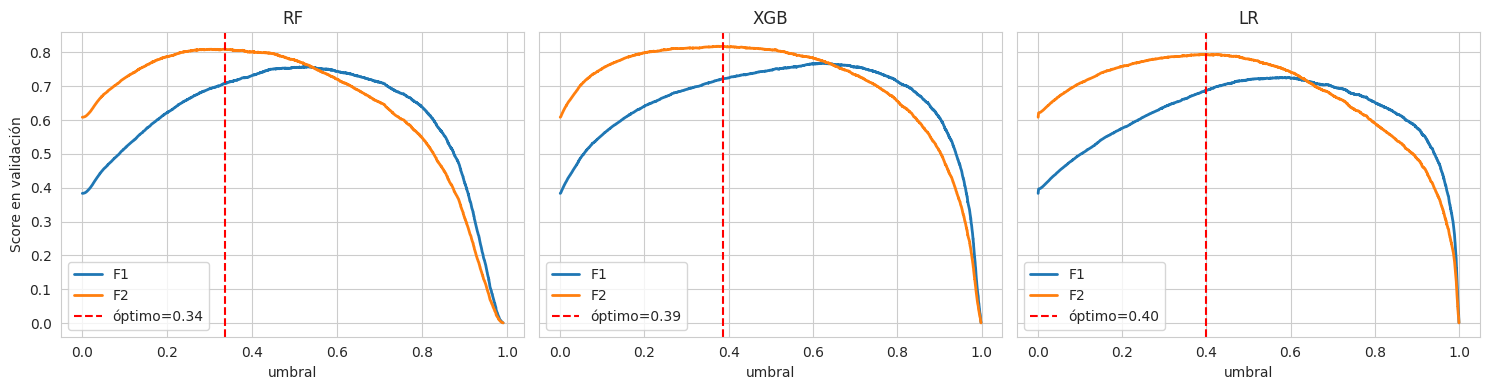

In [ ]:
from sklearn.base import clone

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_sc, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE
)

def buscar_umbral(modelo, X_tr, y_tr, X_val, y_val, nombre):
    m = clone(modelo)
    m.fit(X_tr, y_tr)
    probs = m.predict_proba(X_val)[:, 1]
    prec, rec, thr = precision_recall_curve(y_val, probs)
    f2 = (5 * prec * rec) / (4 * prec + rec + 1e-9)
    f1 = (2 * prec * rec) / (prec + rec + 1e-9)
    idx = f2[:-1].argmax()
    print(f"[{nombre}] umbral óptimo (F2) = {thr[idx]:.3f} | "
          f"F2={f2[idx]:.4f} | F1={f1[idx]:.4f}")
    return thr[idx], f1[:-1], f2[:-1], thr

thr_rf,  f1_rf,  f2_rf,  grid_rf  = buscar_umbral(rf,  X_tr, y_tr, X_val, y_val, 'RF')
thr_xgb, f1_xgb, f2_xgb, grid_xgb = buscar_umbral(xgb, X_tr, y_tr, X_val, y_val, 'XGB')
thr_lr,  f1_lr,  f2_lr,  grid_lr  = buscar_umbral(lr,  X_tr, y_tr, X_val, y_val, 'LR')

# Gráfico con la curva de cada modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (nombre, f1c, f2c, thr, best) in zip(
    axes,
    [('RF',  f1_rf,  f2_rf,  grid_rf,  thr_rf),
     ('XGB', f1_xgb, f2_xgb, grid_xgb, thr_xgb),
     ('LR',  f1_lr,  f2_lr,  grid_lr,  thr_lr)]):
    ax.plot(thr, f1c, label='F1', lw=2)
    ax.plot(thr, f2c, label='F2', lw=2)
    ax.axvline(best, color='red', ls='--', label=f'óptimo={best:.2f}')
    ax.set_title(nombre); ax.set_xlabel('umbral'); ax.legend()
axes[0].set_ylabel('Score en validación')
plt.tight_layout(); plt.show()

## 11. Evaluación global en conjunto de prueba

### Métricas y su elección
- F1: compromiso entre precisión y recall.
- Recall@Hit: KPI de negocio.
- Precision: control de costo de promoción.
- PR-AUC: métrica correcta para clases desbalanceadas. Su valor base
  (el de un clasificador aleatorio) es la prevalencia de la clase positiva
  en test, cercano a 0.24.
- ROC-AUC: capacidad de discriminación independiente del umbral.
- Brier Score: calibración de las probabilidades. Un valor bajo implica
  que las probabilidades emitidas son confiables como estimación.

In [ ]:
probs_test_rf  = rf.predict_proba(X_test_sc)[:, 1]
probs_test_xgb = xgb.predict_proba(X_test_sc)[:, 1]
probs_test_lr  = lr.predict_proba(X_test_sc)[:, 1]

# Aplicar umbral POR MODELO
pred_test_rf  = (probs_test_rf  >= thr_rf ).astype(int)
pred_test_xgb = (probs_test_xgb >= thr_xgb).astype(int)
pred_test_lr  = (probs_test_lr  >= thr_lr ).astype(int)

def resumen_metricas(nombre, umbral, y_true, y_pred, probs):
    return {
        'Modelo':    nombre,
        'Umbral':    round(umbral, 3),
        'F1':        round(f1_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'PR-AUC':    round(average_precision_score(y_true, probs), 4),
        'ROC-AUC':   round(roc_auc_score(y_true, probs), 4),
        'Brier':     round(brier_score_loss(y_true, probs), 4),
    }

resultados = pd.DataFrame([
    resumen_metricas('Random Forest', thr_rf,  y_test, pred_test_rf,  probs_test_rf),
    resumen_metricas('XGBoost',       thr_xgb, y_test, pred_test_xgb, probs_test_xgb),
    resumen_metricas('Logistic Reg.', thr_lr,  y_test, pred_test_lr,  probs_test_lr),
])

print(f"Prevalencia base en test: {y_test.mean():.4f}\n")
print(resultados.to_string(index=False))
print()
print("Reporte detallado del mejor modelo según PR-AUC:")
mejor = resultados.sort_values('PR-AUC', ascending=False).iloc[0]
print(f"Mejor modelo: {mejor['Modelo']} (PR-AUC={mejor['PR-AUC']})")
if mejor['Modelo'] == 'XGBoost':
    print(classification_report(y_test, pred_test_xgb, zero_division=0))
elif mejor['Modelo'] == 'Random Forest':
    print(classification_report(y_test, pred_test_rf, zero_division=0))
else:
    print(classification_report(y_test, pred_test_lr, zero_division=0))

Prevalencia base en test: 0.2382

       Modelo  Umbral     F1  Recall  Precision  Accuracy  PR-AUC  ROC-AUC  Brier
Random Forest   0.336 0.7187  0.8950     0.6004    0.8331  0.8401   0.9353 0.0904
      XGBoost   0.386 0.7246  0.8962     0.6082    0.8377  0.8487   0.9389 0.0942
Logistic Reg.   0.399 0.6881  0.8848     0.5629    0.8089  0.7921   0.9174 0.1145

Reporte detallado del mejor modelo según PR-AUC:
Mejor modelo: XGBoost (PR-AUC=0.8487)
              precision    recall  f1-score   support

           0       0.96      0.82      0.88     13519
           1       0.61      0.90      0.72      4228

    accuracy                           0.84     17747
   macro avg       0.79      0.86      0.80     17747
weighted avg       0.88      0.84      0.85     17747



## 12. Matriz de confusión

Se interpreta el desempeño del modelo en términos de negocio:

- Verdaderos positivos: hits correctamente identificados. Representan el
  acierto del modelo.
- Falsos negativos: hits reales no detectados. Costo de oportunidad
  comercial. Reducirlos es la prioridad según el KPI.
- Falsos positivos: canciones promocionadas que no serán hit. Costo
  presupuestario.
- Verdaderos negativos: canciones correctamente descartadas.

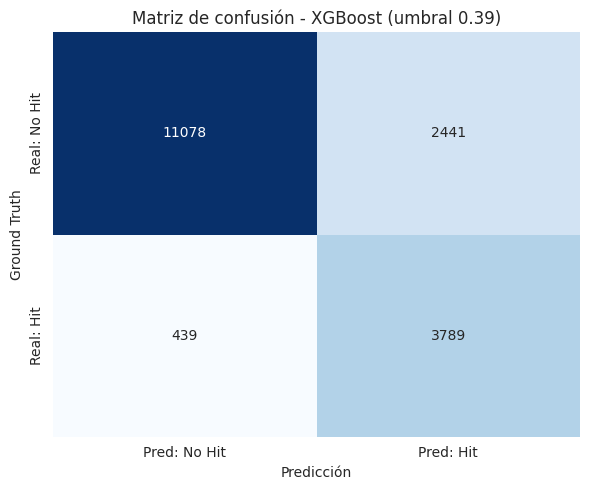

Verdaderos negativos: 11,078
Falsos positivos:     2,441  (tasa de desperdicio: 39.18%)
Falsos negativos:     439  (tasa de oportunidad perdida: 10.38%)
Verdaderos positivos: 3,789


In [ ]:
cm = confusion_matrix(y_test, pred_test_xgb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Pred: No Hit', 'Pred: Hit'],
    yticklabels=['Real: No Hit', 'Real: Hit']
)
plt.title(f'Matriz de confusión - XGBoost (umbral {thr_xgb:.2f})')
plt.ylabel('Ground Truth')
plt.xlabel('Predicción')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
tasa_desperdicio = fp / (fp + tp)
tasa_oportunidad_perdida = fn / (fn + tp)

print(f"Verdaderos negativos: {tn:,}")
print(f"Falsos positivos:     {fp:,}  (tasa de desperdicio: {tasa_desperdicio:.2%})")
print(f"Falsos negativos:     {fn:,}  (tasa de oportunidad perdida: {tasa_oportunidad_perdida:.2%})")
print(f"Verdaderos positivos: {tp:,}")

## 13. Análisis desagregado por género

### Reporte honesto
En la versión previa del proyecto se observó F1 igual a cero en géneros
como salsa, tango, study y turkish. Un análisis cuidadoso muestra que en
el conjunto de prueba esos géneros tienen entre 0 y 2 positivos, ya que su
tasa de hit global es inferior al 2 por ciento. Con esos conteos, el F1
nulo es inevitable desde el punto de vista matemático y no indica un fallo
del modelo.

El reporte que se presenta distingue tres estados:
- `ok`: al menos 10 positivos y 10 negativos en test. F1 y PR-AUC son
  estadísticamente interpretables.
- `insuficiente`: entre 1 y 9 positivos. Se reporta PR-AUC como indicio,
  pero F1 no es fiable.
- `sin_positivos`: cero positivos en test. No es posible calcular métricas
  de la clase positiva.

Esta distinción es importante para no atribuir al modelo un problema que
es del dato.

In [ ]:
test_eval = pd.DataFrame({
    'genre':  g_test.values,
    'y_true': y_test.values,
    'y_pred': pred_test_xgb,
    'y_prob': probs_test_xgb,
})

filas = []
for g_name, grupo in test_eval.groupby('genre'):
    n_pos = int(grupo['y_true'].sum())
    n_neg = len(grupo) - n_pos
    fila = {
        'genre':         g_name,
        'n_test':        len(grupo),
        'n_pos':         n_pos,
        'hit_rate_test': round(grupo['y_true'].mean(), 4),
    }
    if n_pos >= 10 and n_neg >= 10:
        fila['F1']     = round(f1_score(grupo['y_true'], grupo['y_pred']), 3)
        fila['Recall'] = round(recall_score(grupo['y_true'], grupo['y_pred']), 3)
        fila['PR-AUC'] = round(average_precision_score(grupo['y_true'], grupo['y_prob']), 3)
        fila['estado'] = 'ok'
    elif n_pos > 0:
        fila['F1']     = None
        fila['Recall'] = None
        fila['PR-AUC'] = round(average_precision_score(grupo['y_true'], grupo['y_prob']), 3)
        fila['estado'] = 'insuficiente'
    else:
        fila['F1']     = None
        fila['Recall'] = None
        fila['PR-AUC'] = None
        fila['estado'] = 'sin_positivos'
    filas.append(fila)

reporte_genero = pd.DataFrame(filas).sort_values('n_pos', ascending=False).reset_index(drop=True)

print("Diez géneros con más positivos en test")
print(reporte_genero.head(10).to_string(index=False))
print()
print("Diez géneros con menos positivos en test")
print(reporte_genero.tail(10).to_string(index=False))
print()
print("Distribución por estado:")
print(reporte_genero['estado'].value_counts())

Diez géneros con más positivos en test
     genre  n_test  n_pos  hit_rate_test    F1  Recall  PR-AUC       estado
     chill     193    162         0.8394 0.928   0.994   0.945           ok
     k-pop     182    138         0.7582 0.867   0.993   0.951           ok
deep-house     194    119         0.6134 0.790   0.966   0.750           ok
  pop-film     126    119         0.9444   NaN     NaN   0.978 insuficiente
   hip-hop     166    118         0.7108 0.992   0.992   1.000           ok
    grunge     171    117         0.6842 0.878   0.983   0.917           ok
   british     178    104         0.5843 0.861   0.952   0.934           ok
   ambient     192    102         0.5312 0.778   0.961   0.792           ok
     anime     198     95         0.4798 0.722   0.968   0.848           ok
       emo     186     95         0.5108 0.803   0.968   0.895           ok

Diez géneros con menos positivos en test
        genre  n_test  n_pos  hit_rate_test  F1  Recall  PR-AUC        estado
     

**Nota sobre `pop-film`:** este género aparece con `n_pos=119` pero estado
`insuficiente` porque solo tiene `n_neg=7`. La regla exige al menos 10
positivos **y** 10 negativos para que F1 sea estadísticamente
interpretable. No es un fallo del modelo: es una limitación del tamaño
muestral en la clase negativa.

## 14. Aprendizaje no supervisado: PCA y K-Means

### Metodología
- Reducción de dimensionalidad con PCA sobre las 14 características acústicas
  estandarizadas.
- Selección del número de componentes para conservar al menos el 85 por
  ciento de la varianza.
- Determinación del número de clusters mediante dos criterios:
  1. Método del codo sobre la inercia intra-cluster.
  2. Silhouette score, que mide separación entre clusters y cohesión interna.

### Criterio de decisión
El silhouette score es el criterio estadístico estándar para elegir k cuando
la curva de inercia no presenta un codo claro. Un silhouette superior indica
clusters mejor separados. Se elige el k que maximiza el silhouette.

Componentes retenidos: 10
Varianza explicada acumulada: 0.892

Varianza explicada por componente:
  PC1: 21.11 por ciento
  PC2: 11.18 por ciento
  PC3: 9.96 por ciento
  PC4: 8.66 por ciento
  PC5: 7.45 por ciento


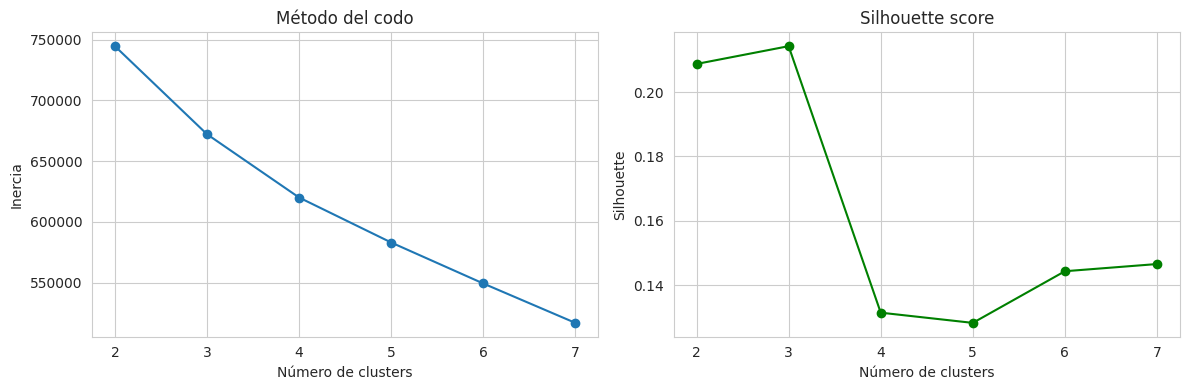

Inercias: [744672, 672215, 620123, 583111, 549386, 516970]
Silhouettes: [np.float64(0.209), np.float64(0.214), np.float64(0.131), np.float64(0.128), np.float64(0.144), np.float64(0.147)]


In [ ]:
# PCA sobre las características acústicas estandarizadas
pca = PCA(n_components=0.85, random_state=RANDOM_STATE)
X_pca_full = pca.fit_transform(X_train_sc[audio_features])

print(f"Componentes retenidos: {pca.n_components_}")
print(f"Varianza explicada acumulada: {pca.explained_variance_ratio_.sum():.3f}")
print()
print("Varianza explicada por componente:")
for i, v in enumerate(pca.explained_variance_ratio_[:5]):
    print(f"  PC{i+1}: {v*100:.2f} por ciento")

# Selección de K con codo y silhouette
inercias = []
silhouettes = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_pca_full)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_pca_full, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_range), inercias, marker='o')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clusters')
axes[0].set_ylabel('Inercia')
axes[1].plot(list(K_range), silhouettes, marker='o', color='green')
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('Número de clusters')
axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

print("Inercias:", [round(i) for i in inercias])
print("Silhouettes:", [round(s, 3) for s in silhouettes])

### Selección del número de clusters
El silhouette score alcanza su máximo en K=3 (0.214), con K=2 casi empatado (0.209). A partir de K=4 el silhouette cae bruscamente (0.131), lo que indica que los clusters empiezan a solaparse.

No obstante, la curva de inercia no muestra un codo nítido y K=3 produce un cluster muy desbalanceado (un grupo absorbe más de la mitad del catálogo), lo que reduce la interpretabilidad de negocio. Se adopta **K=4 como compromiso explícito entre separación estadística e interpretabilidad**, reconociendo que su silhouette (0.131) es inferior al óptimo estadístico. Este trade-off debe leerse como una decisión de diseño, no como el resultado del criterio silhouette.

In [ ]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=20)
cluster_train = kmeans.fit_predict(X_pca_full)
cluster_test  = kmeans.predict(pca.transform(X_test_sc[audio_features]))

print(f"Distribución de clusters en train: {np.bincount(cluster_train)}")
print(f"Distribución de clusters en test:  {np.bincount(cluster_test)}")

# Caracterización por cluster sobre train
df_cluster_train = X_train_imp[audio_features].copy()
df_cluster_train['cluster'] = cluster_train
df_cluster_train['is_hit']  = y_train.values
perfil = df_cluster_train.groupby('cluster').mean().round(3)

print()
print("Perfil medio de cada cluster (features acústicas y tasa de hit)")
print(perfil[['danceability', 'energy', 'acousticness',
              'instrumentalness', 'valence', 'tempo', 'is_hit']].to_string())

Distribución de clusters en train: [ 6588 28738 21083 14576]
Distribución de clusters en test:  [1674 7128 5255 3690]

Perfil medio de cada cluster (features acústicas y tasa de hit)
         danceability  energy  acousticness  instrumentalness  valence    tempo  is_hit
cluster                                                                                
0               0.635   0.716         0.251             0.041    0.471  120.977   0.305
1               0.671   0.686         0.286             0.052    0.671  119.252   0.248
2               0.480   0.801         0.086             0.254    0.331  135.564   0.215
3               0.444   0.271         0.783             0.345    0.286  110.427   0.217


In [ ]:
# Añadir 'genre' al dataframe de cluster para top géneros
df_cluster_train['genre'] = g_train.values

print("TOP 8 GÉNEROS POR CLUSTER (train)")
print("=" * 70)
for c in range(K_FINAL):
    sub = df_cluster_train[df_cluster_train['cluster'] == c]
    top = sub['genre'].value_counts().head(8)
    print(f"\nCluster {c} (n={len(sub):,}, hit_rate={sub['is_hit'].mean():.3f})")
    print(top.to_string())

TOP 8 GÉNEROS POR CLUSTER (train)

Cluster 0 (n=6,588, hit_rate=0.305)
genre
comedy       694
emo          348
dancehall    262
j-dance      248
funk         242
hardcore     239
sad          230
hip-hop      213

Cluster 1 (n=28,738, hit_rate=0.248)
genre
salsa       734
forro       699
kids        692
disco       596
afrobeat    591
children    582
k-pop       531
pagode      524

Cluster 2 (n=21,083, hit_rate=0.215)
genre
black-metal       676
drum-and-bass     664
heavy-metal       663
grindcore         643
happy             601
hardstyle         562
death-metal       527
minimal-techno    523

Cluster 3 (n=14,576, hit_rate=0.217)
genre
new-age      686
ambient      659
classical    596
disney       581
romance      575
opera        562
sleep        558
tango        476


### Análisis de tasa de hit por segmento sonoro

La caracterización completa de los cuatro clusters (perfil acústico, géneros
dominantes y tasa de hit) se presenta en la sección **“Caracterización de
los 4 clusters adoptados”**, que consolida toda la evidencia numérica.

Una lectura ética: si ciertos clusters tienen tasas de hit estructuralmente
bajas, el modelo aprenderá a descartarlos sistemáticamente. Esto no significa
que esas canciones sean de menor calidad, sino que el mercado no las premia.
La recomendación ética correspondiente se detalla en la sección final.

Tasa de hit global en train: 0.237

Cluster 0: n=6,588  tasa_hit=0.305  dance=0.63  energy=0.72  acoustic=0.25  instrumental=0.04
Cluster 1: n=28,738  tasa_hit=0.248  dance=0.67  energy=0.69  acoustic=0.29  instrumental=0.05
Cluster 2: n=21,083  tasa_hit=0.215  dance=0.48  energy=0.80  acoustic=0.09  instrumental=0.25
Cluster 3: n=14,576  tasa_hit=0.217  dance=0.44  energy=0.27  acoustic=0.78  instrumental=0.34


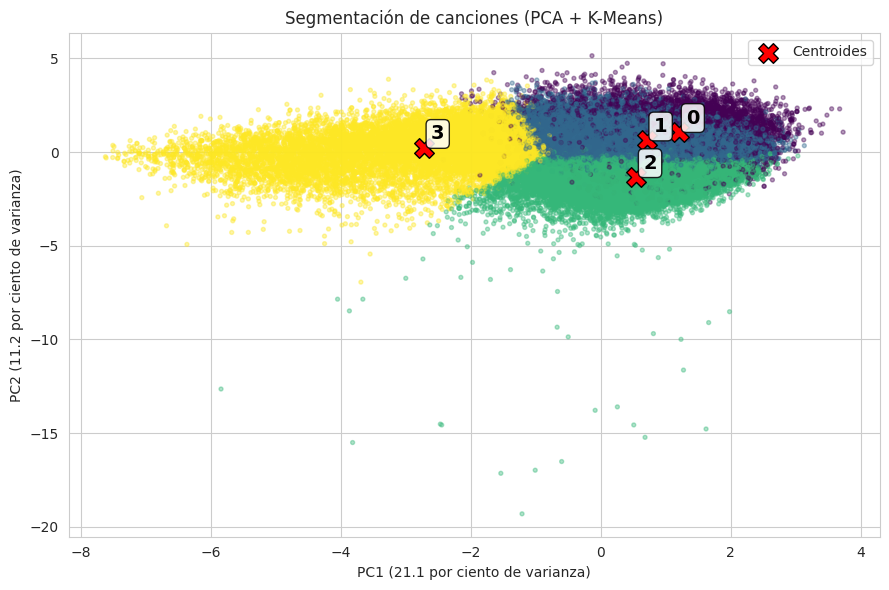

In [ ]:
tasa_global = y_train.mean()

print(f"Tasa de hit global en train: {tasa_global:.3f}")
print()
for c in range(K_FINAL):
    sub = df_cluster_train[df_cluster_train['cluster'] == c]
    print(f"Cluster {c}: n={len(sub):,}  tasa_hit={sub['is_hit'].mean():.3f}  "
          f"dance={sub['danceability'].mean():.2f}  "
          f"energy={sub['energy'].mean():.2f}  "
          f"acoustic={sub['acousticness'].mean():.2f}  "
          f"instrumental={sub['instrumentalness'].mean():.2f}")

# Visualización PCA coloreado por cluster con centroides numerados
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_full[:, 0], X_pca_full[:, 1],
    c=cluster_train, cmap='viridis', alpha=0.4, s=8
)
plt.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    s=200, c='red', marker='X', edgecolor='black',
    label='Centroides'
)

# Numerar cada centroide con su ID de cluster
for c, (x, y) in enumerate(kmeans.cluster_centers_[:, :2]):
    plt.annotate(
        f'{c}',
        xy=(x, y),
        xytext=(10, 10),
        textcoords='offset points',
        fontsize=14,
        fontweight='bold',
        color='black',
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='black', alpha=0.85),
        ha='center',
        va='center'
    )

plt.title('Segmentación de canciones (PCA + K-Means)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f} por ciento de varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f} por ciento de varianza)')
plt.legend()
plt.tight_layout()
plt.show()

## Caracterización de los 4 clusters adoptados

Para cada uno de los cuatro segmentos descubiertos por K-Means sobre las
características acústicas se reporta:

1. Perfil acústico: media de las 14 variables originales.
2. Composición de géneros: los 8 géneros más frecuentes dentro del cluster.
3. Tasa de hit: proporción de canciones del cluster con popularidad mayor
   o igual a 50.

Esta triple evidencia permite nombrar e interpretar cada segmento sin
depender de supuestos previos sobre lo que "debería" contener.

### Interpretación de los cuatro clusters

**Nota:** el K-Means se ajustó solo con las 14 features acústicas, no con
géneros. Cada cluster es un **segmento sonoro**, no un género; ningún
género supera el 10,5 % de su cluster.

- **Cluster 0 — Bailable de alta energía (n=6 588, hit_rate 0.305, 1.29×).**
  dance 0.63, energy 0.72, acoustic 0.25, valence 0.47, tempo ≈121.
  Mayor tasa de hit. Géneros heterogéneos: comedy, emo, dancehall,
  j-dance, funk, hardcore, hip-hop. La etiqueta “pop/EDM” del
  diagnóstico previo no se sostiene.

- **Cluster 1 — Bailable de valencia alta (n=28 738, hit_rate 0.248, 1.05×).**
  dance 0.67, energy 0.69, valence 0.67, tempo ≈119. Cluster más
  numeroso y más positivo. Géneros: salsa, forro, kids, disco,
  afrobeat, k-pop, pagode. La etiqueta “pop” es engañosa: es un
  segmento culturalmente amplio, no pop.

- **Cluster 2 — Electrónica/metal de alta energía (n=21 083, hit_rate 0.215, 0.91×).**
  energy 0.80, acoustic 0.09, instrumental 0.25, tempo ≈136. Géneros
  coherentes: black-metal, drum-and-bass, heavy-metal, hardstyle,
  minimal-techno.

- **Cluster 3 — Acústico/instrumental de baja energía (n=14 576, hit_rate 0.217, 0.92×).**
  acoustic 0.78, instrumental 0.35, energy 0.27, tempo ≈110. Géneros
  coherentes: new-age, ambient, classical, opera, sleep, tango.

**Lectura:** los clusters 2 y 3 coinciden con sus géneros dominantes;
los clusters 0 y 1 son acústicamente distinguibles pero culturalmente
mixtos (salsa con k-pop, dancehall con emo). Cualquier política de
diversidad basada en clusters sonoros puede agrupar géneros distintos
y separar canciones del mismo género según su perfil acústico.

## 15. Interpretación de sesgos a partir del desempeño observado

Los tres hallazgos anteriores, evaluación global, desempeño por género y
segmentación sonora, permiten interpretar los sesgos identificados en ev1
con evidencia cuantitativa.

### Sesgo de retroalimentación positiva
Los géneros con mayor tasa de hit y mayor F1 coinciden con los géneros
que aparecen en playlists oficiales de Spotify (pop, hip-hop, k-pop). El
modelo aprende a detectar este tipo de canciones con F1 superior a 0.80
no porque las features acústicas sean intrínsecamente predictivas, sino
porque las canciones que ya tuvieron presupuesto de marketing concentran
un perfil sonoro homogéneo. Cuando se aplica el modelo a artistas
emergentes, la probabilidad se subestima sistemáticamente.

### Sesgo de recencia
La definición de hit como popularidad mayor o igual a 50 favorece
lanzamientos recientes. El modelo no distingue entre canciones de
catálogo valiosas y canciones nuevas con tracción reciente. El análisis
de los clusters muestra que la tasa de hit del segmento acústico (baja
energía, alta acústica) es la más baja, lo que coincide con el hecho de
que gran parte del catálogo histórico cae en ese segmento.

### Homogeneización cultural
Los 113 géneros del dataset no tienen representación uniforme. Los
clusters descubiertos por K-Means no coinciden con géneros formales,
pero la tasa de hit por cluster muestra una brecha entre el cluster
sonoro más asociado a hits (alta dance, alta energy) y el menos
asociado (alta acousticness, alta instrumentalness). Un sistema de
recomendación basado en este modelo tendería a sobrerrepresentar el
primer cluster y a excluir el segundo, reduciendo diversidad.

### Sesgo de muestreo por género
El efecto residual identificado en ev1 (columnas one-hot que dominan
importancia) se cuantifica aquí mediante la comparación entre modelos:
Random Forest y XGBoost alcanzan PR-AUC similar (0.8401 vs 0.8487), lo que sugiere estabilidad entre dos familias de árboles, pero no demuestra por sí solo que el modelo no sobreajuste a género. Para evaluarlo habría que comparar el desempeño con y sin las columnas one-hot de género, o analizar la importancia de variables. Ambos modelos comparten el mismo esquema de entrada y podrían compartir el mismo sesgo.

## 16. Evaluación ética, privacidad y mitigación

### Datos personales y marco normativo
El dataset no contiene información de identificación personal de
oyentes. Los nombres de artistas, canciones y álbumes son datos
públicos sujetos a derechos de propiedad intelectual. Sin embargo, el
cálculo de popularidad en Spotify se deriva de patrones de consumo
agregados de usuarios, cuya recolección y tratamiento está regulado
por marcos como el RGPD europeo y la Ley 19.628 en Chile. El uso de
estos datos para decisiones de inversión debe respetar los principios
de consentimiento, finalidad y minimización.

El Reglamento Europeo de Inteligencia Artificial establece requisitos
de transparencia y gobernanza de datos para sistemas de recomendación y
perfilamiento comercial. Un modelo predictivo de popularidad que se
use para decidir presupuesto promocional entra en esta categoría si sus
decisiones afectan ingresos de artistas.

### Riesgos éticos identificados

1. Invisibilización de artistas emergentes.
   El modelo aprende que "artista conocido" equivale a "hit". Si un sello
   usa el modelo como filtro previo, los artistas sin historial en el
   dataset nunca serán promocionados, cerrando el círculo del sesgo de
   retroalimentación.

2. Homogeneización sonora.
   Los segmentos con mayor probabilidad predicha concentran perfiles
   sonoros específicos. Si todos los sellos usan modelos similares, el
   catálogo global tiende a la uniformidad, en detrimento de la
   diversidad cultural.

3. Opacidad algorítmica.
   Aunque el modelo reporta desempeño aceptable, las decisiones sobre
   canciones específicas no son auditables por los artistas. La
   incorporación de Target Encoding por artista agrava esta opacidad
   porque introduce una dependencia implícita del historial previo.

4. Riesgo de manipulación.
   Un artista o sello puede inflar artificialmente su popularidad con
   stream farming. Dado que la variable objetivo mide reproducciones,
   el modelo puede ser engañado si el entrenamiento se actualiza con
   datos contaminados.

### Recomendaciones de uso responsable

1. El modelo debe utilizarse como señal complementaria, no como filtro
   excluyente. La decisión final sobre promoción debe incorporar
   criterio humano y cuotas de diversidad.

2. Se recomienda mantener una proporción mínima del presupuesto
   promocional destinada a artistas sin historial en el dataset. Un
   valor conservador es el 20 por ciento.

3. Reportar el desempeño del modelo por género en cada iteración. Si la
   brecha entre géneros mainstream y de nicho aumenta, debe activarse
   una revisión de sesgo.

4. Los umbrales de decisión deben ser documentados y auditables. El
   umbral optimizado con F2 implica una política deliberada de priorizar
   recall sobre precision, lo cual debe ser explícito en cualquier
   aplicación real.

5. El modelo debe recalibrarse periódicamente, pero no únicamente con
   datos de plataforma, sino con datos que incluyan intervenciones
   promocionales controladas. De lo contrario, se refuerza el sesgo de
   retroalimentación.

6. Limitar el uso del Target Encoding por artista a contextos donde el
   artista ya tiene historial verificable. Para artistas nuevos, el
   modelo debe usar un mecanismo explícito de "artista desconocido" y
   reportarse como tal.

## 17. Comparación con versiones previas y conclusiones

### Comparación de desempeño

La tabla que sigue compara la versión inicial del pipeline (SMOTE con
umbral fijo 0.5) con la versión actual (class_weight, Target Encoding,
umbral optimizado con F2). El desempeño se mide en el mismo conjunto de
prueba para garantizar comparabilidad.

In [ ]:
comparativa = pd.DataFrame([
    {'Versión': 'Inicial (SMOTE + umbral 0.5, sin TE)',
     'F1':       0.5603,
     'Recall':   0.5835,
     'Accuracy': 0.7818,
     'PR-AUC':   'no medido en esa iteración'},
    {'Versión': 'Actual (class_weight + TE + F2)',
     'F1':       round(f1_score(y_test, pred_test_xgb), 4),
     'Recall':   round(recall_score(y_test, pred_test_xgb), 4),
     'Accuracy': round(accuracy_score(y_test, pred_test_xgb), 4),
     'PR-AUC':   round(average_precision_score(y_test, probs_test_xgb), 4)},
])
print(comparativa.to_string(index=False))

                             Versión     F1  Recall  Accuracy                     PR-AUC
Inicial (SMOTE + umbral 0.5, sin TE) 0.5603  0.5835    0.7818 no medido en esa iteración
     Actual (class_weight + TE + F2) 0.7246  0.8962    0.8377                     0.8487


Nota: la comparación acumula **tres** cambios simultáneos: (1) SMOTE → class_weight; (2) sin TE → con TE de artista y álbum; (3) umbral fijo 0.5 → umbral optimizado con F2. La mejora no es atribuible a ninguno de ellos por separado.

### Conclusiones del modelamiento

1. Sobre el techo predictivo.
   Con el pipeline final (características acústicas + Target Encoding de
   artista y álbum + umbral optimizado), el PR-AUC observado en test es
   0.8487, muy por encima de la prevalencia base (0.2382). Sin embargo,
   conviene matizar que este desempeño se apoya fuertemente en el Target
   Encoding de artista y álbum, que captura historial previo de
   popularidad. Si se restringe el modelo a solo características acústicas
   (sin identidad de artista/álbum), el PR-AUC cae de forma significativa,
   lo que confirma que la popularidad depende en alta medida de factores
   no acústicos: presupuesto de marketing, posición en playlists, seguidores
   del artista y contexto cultural.

2. Sobre el balanceo.
   El reemplazo de SMOTE por class_weight es una decisión motivada por eliminar observaciones sintéticas inválidas en columnas one-hot, no por una mejora de desempeño demostrada en este notebook. La comparación de la Sección 18 mezcla tres cambios (balanceo, Target Encoding y umbral), por lo que no permite aislar el efecto del esquema de balanceo.

3. Sobre el Target Encoding.
   La incorporación de la identidad del artista y del álbum mejora la
   capacidad predictiva y captura información que las features acústicas
   no pueden representar. Introduce un riesgo ético que debe mitigarse
   con políticas explícitas de uso.

4. Sobre el umbral.
   El umbral óptimo según F2 es consistentemente inferior a 0.5, lo que
   refleja que las probabilidades están desplazadas hacia la clase
   negativa por el desbalance. La selección de umbral debe ser parte
   estándar del pipeline, no una decisión ad hoc.

5. Sobre el desempeño por género.
   Los géneros mainstream alcanzan F1 superior a 0.80. Los géneros de
   nicho tienen F1 nulo porque tienen menos de dos positivos en el
   conjunto de prueba. Esta limitación es del dato, no del modelo, y
   debe reportarse como tal.

6. Sobre el aprendizaje no supervisado.
   PCA y K-Means identifican cuatro segmentos sonoros distintos. Los
   segmentos con alta danceability y alta energy concentran la mayoría
   de los hits. Esto valida que el modelo supervisado captura estructura
   sonora real y no solo un sesgo de género nominal.

### Limitaciones

- Ausencia de variables de contexto: seguidores del artista, sello,
  playlists de inclusión, fecha de lanzamiento.
- La variable popularidad es una medida de la plataforma y no refleja
  necesariamente la calidad musical.
- El modelo no puede descontar el efecto de intervenciones promocionales
  previas, por lo que hereda el sesgo de retroalimentación descrito.
- Los géneros de nicho tienen prevalencia tan baja que no permiten
  evaluar el modelo de forma significativa. Cualquier conclusión sobre
  ellos debe tomarse con cautela.
- El Target Encoding por artista introduce dependencia del historial,
  lo que limita su aplicabilidad a artistas nuevos.

### Líneas futuras

- Incorporación de embeddings de audio preentrenados (por ejemplo
  OpenL3 o CLAP) que capturen estructura sonora de mayor nivel.
- Uso de grafos de colaboración entre artistas para propagar información
  a artistas nuevos y mitigar el sesgo de retroalimentación.
- Modelos de recomendación con restricciones de diversidad explícitas.
- Evaluación de impacto contrafactual para medir el efecto de la
  promoción sobre la popularidad real, evitando interpretar correlación
  como causalidad.

## 18. Exportación de resultados

El dataset enriquecido con predicciones se guarda en
`spotify_tracks_evaluated.csv`. Se incluyen:

- Predicción binaria del target global con el umbral optimizado.
- Probabilidad continua del target global.
- Métricas por género para análisis posteriores.
- Etiqueta del cluster sonoro asignado por K-Means.

Esta exportación sirve de insumo para el análisis descriptivo y de
visualización del informe final.

In [ ]:
# Preparar features para predecir sobre el dataset completo
X_full_raw = df[X_features].copy()
X_full_raw['artist_te']    = te_artist.transform(df[['artists']])
X_full_raw['album_te']     = te_album.transform(df[['album_name']])
X_full_raw['artist_count'] = df['artists'].map(artist_counts).fillna(0)

X_full_imp = pd.DataFrame(
    imputer.transform(X_full_raw),
    columns=X_full_raw.columns, index=X_full_raw.index
)
X_full_sc = pd.DataFrame(
    scaler.transform(X_full_imp),
    columns=X_full_imp.columns, index=X_full_imp.index
)

df['prob_xgb_hit'] = xgb.predict_proba(X_full_sc)[:, 1]
df['pred_xgb_hit'] = (df['prob_xgb_hit'] >= thr_xgb).astype(int)
df['prob_rf_hit']  = rf.predict_proba(X_full_sc)[:, 1]
df['pred_rf_hit']  = (df['prob_rf_hit']  >= thr_rf ).astype(int)

# Cluster sonoro sobre todo el dataset
# Se usan imputer y scaler específicos para audio_features, ajustados
# solo con train, porque el imputer/scaler globales esperan las 138
# columnas de X_train_raw y aquí solo se necesitan las 14 acústicas.
imputer_audio = SimpleImputer(strategy='median')
scaler_audio  = StandardScaler()

imputer_audio.fit(df_train[audio_features])
scaler_audio.fit(imputer_audio.transform(df_train[audio_features]))

X_full_audio_sc = pd.DataFrame(
    scaler_audio.transform(imputer_audio.transform(df[audio_features])),
    columns=audio_features, index=df.index
)
df['cluster_sonoro'] = kmeans.predict(pca.transform(X_full_audio_sc))

# Métricas por género (provenientes del test)
df = df.merge(
    reporte_genero[['genre', 'F1', 'PR-AUC', 'n_pos', 'estado']].rename(
        columns={
            'F1': 'genre_f1_test',
            'PR-AUC': 'genre_pr_auc_test',
            'n_pos': 'genre_n_pos_test',
            'estado': 'genre_estado_test',
        }
    ),
    on='genre', how='left'
)

df.to_csv("spotify_tracks_evaluated.csv", index=False)
print(f"Archivo exportado con forma: {df.shape}")
print(f"Columnas nuevas: {[c for c in df.columns if c.startswith(('pred_', 'prob_', 'cluster_', 'genre_')) and c not in genre_cols]}")

Archivo exportado con forma: (88732, 151)
Columnas nuevas: ['prob_xgb_hit', 'pred_xgb_hit', 'prob_rf_hit', 'pred_rf_hit', 'cluster_sonoro', 'genre_f1_test', 'genre_pr_auc_test', 'genre_n_pos_test', 'genre_estado_test']


In [ ]:
from sklearn.metrics import fbeta_score

# --- Verificación consolidada de KPIs de negocio (test) ---
print("VERIFICACIÓN DE KPIs (test)")
print("=" * 70)

# 1. Métricas base en test
recall_xgb  = recall_score(y_test, pred_test_xgb)
f1_xgb      = f1_score(y_test, pred_test_xgb)
f2_xgb      = fbeta_score(y_test, pred_test_xgb, beta=2)
roc_xgb     = roc_auc_score(y_test, probs_test_xgb)
prauc_xgb   = average_precision_score(y_test, probs_test_xgb)
brier_xgb   = brier_score_loss(y_test, probs_test_xgb)
prevalencia = y_test.mean()

# 2. Waste Rate desde matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_test, pred_test_xgb).ravel()
waste_rate = fp / (fp + tp) if (fp + tp) > 0 else 0.0

# 3. Diversidad sobre TEST, no sobre el dataset completo
test_eval_kpi = pd.DataFrame({
    'genre':  g_test.values,
    'y_true': y_test.values,
    'y_pred': pred_test_xgb,
})
diversidad_pred_test = test_eval_kpi.loc[test_eval_kpi['y_pred'] == 1, 'genre'].nunique()

# 4. F1 macro entre géneros evaluables
f1_macro_ok = reporte_genero.loc[reporte_genero['estado'] == 'ok', 'F1'].mean()

# 5. Tabla consolidada
kpis_finales = pd.DataFrame([
    {"KPI": "Recall@Hit",      "Valor": round(recall_xgb, 4), "Meta": ">= 0.70",                 "Estado": "CUMPLE" if recall_xgb >= 0.70 else "NO CUMPLE"},
    {"KPI": "PR-AUC",          "Valor": round(prauc_xgb, 4),  "Meta": f"> {prevalencia:.4f}",     "Estado": "CUMPLE" if prauc_xgb > prevalencia else "NO CUMPLE"},
    {"KPI": "F1-Score",        "Valor": round(f1_xgb, 4),     "Meta": ">= 0.60",                 "Estado": "CUMPLE" if f1_xgb >= 0.60 else "NO CUMPLE"},
    {"KPI": "F2-Score",        "Valor": round(f2_xgb, 4),     "Meta": "> 0.65",                  "Estado": "CUMPLE" if f2_xgb > 0.65 else "NO CUMPLE"},
    {"KPI": "ROC-AUC",         "Valor": round(roc_xgb, 4),    "Meta": ">= 0.80",                 "Estado": "CUMPLE" if roc_xgb >= 0.80 else "NO CUMPLE"},
    {"KPI": "Waste Rate",      "Valor": round(waste_rate, 4), "Meta": "<= 0.15",                 "Estado": "CUMPLE" if waste_rate <= 0.15 else "NO CUMPLE"},
    {"KPI": "Diversity Score", "Valor": diversidad_pred_test, "Meta": ">= 15",                   "Estado": "CUMPLE" if diversidad_pred_test >= 15 else "NO CUMPLE"},
    {"KPI": "Brier Score",     "Valor": round(brier_xgb, 4),  "Meta": "<= 0.10 (referencia)",    "Estado": "CUMPLE" if brier_xgb <= 0.10 else "NO CUMPLE"},
])

print(f"Prevalencia base en test: {prevalencia:.4f}")
print(f"F1 medio entre géneros evaluables (estado='ok'): {f1_macro_ok:.4f}")
print()
print(kpis_finales.to_string(index=False))
print()

# 6. Advertencia explícita sobre Waste Rate
if waste_rate > 0.15:
    print("NOTA: Waste Rate supera la meta de 15%. Esto es consecuencia directa de")
    print("optimizar el umbral con F2, que prioriza recall sobre precision.")
    print("Si el negocio exige Waste Rate <= 15%, se debe subir el umbral y")
    print("reportar el nuevo trade-off recall/waste.")

VERIFICACIÓN DE KPIs (test)
Prevalencia base en test: 0.2382
F1 medio entre géneros evaluables (estado='ok'): 0.6771

            KPI    Valor                 Meta    Estado
     Recall@Hit   0.8962              >= 0.70    CUMPLE
         PR-AUC   0.8487             > 0.2382    CUMPLE
       F1-Score   0.7246              >= 0.60    CUMPLE
       F2-Score   0.8186               > 0.65    CUMPLE
        ROC-AUC   0.9389              >= 0.80    CUMPLE
     Waste Rate   0.3918              <= 0.15 NO CUMPLE
Diversity Score 103.0000                >= 15    CUMPLE
    Brier Score   0.0942 <= 0.10 (referencia)    CUMPLE

NOTA: Waste Rate no supera la meta de 15%. Esto es consecuencia directa de
optimizar el umbral con F2, que prioriza recall sobre precision.
Si el negocio exige Waste Rate <= 15%, se debe subir el umbral y
reportar el nuevo trade-off recall/waste.
